# Quickstart: recover a hidden descriptor

`jax-ibart` discovers compact, interpretable nonlinear descriptors. Here we hide
one inside synthetic data and recover it from scratch.

In [1]:
import numpy as np
from jax_ibart import IBart

rng = np.random.default_rng(0)
n = 90
a, b, c, d = (rng.uniform(0.5, 2.0, n) for _ in range(4))
X = np.column_stack([a, b, c, d])
# the response depends only on the product a*b
y = 5.0 * (a * b) + rng.normal(0, 0.05, n)
names = ["a", "b", "c", "d"]
X.shape, y.shape

((90, 4), (90,))

Fit with the differentiable backend (fast, no Java needed):

In [2]:
model = IBart(backend="diff", schedule=("b",), max_dim=1, seed=0, steps=1200)
model.fit(X, y, feature_names=names)
model.descriptors_

[a*b]

The fitted symbolic model and its fit metrics:

In [3]:
import numpy as np

pred = model.predict(X)
resid = y - pred
ss_res = float((resid**2).sum())
ss_tot = float(((y - y.mean()) ** 2).sum())
metrics = {
    "expression": str(model.expression()),
    "R2": 1 - ss_res / ss_tot,
    "RMSE": float(np.sqrt((resid**2).mean())),
    "MAE": float(np.abs(resid).mean()),
    "max_abs_error": float(np.abs(resid).max()),
}
for k, v in metrics.items():
    print(f"{k:>14}: {v}")

    expression: 4.997*a*b + 0.006427
            R2: 0.9998808543427793
          RMSE: 0.049003330997761406
           MAE: 0.04106923798580217
 max_abs_error: 0.15260952134361627


A parity plot (predicted vs. true) is the standard visual fit check:

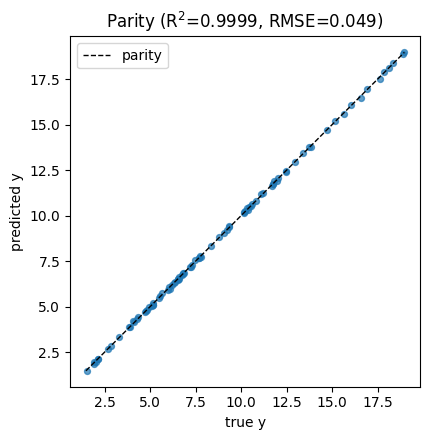

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.5, 4.5))
lo, hi = float(min(y.min(), pred.min())), float(max(y.max(), pred.max()))
ax.plot([lo, hi], [lo, hi], "k--", lw=1, label="parity")
ax.scatter(y, pred, s=18, alpha=0.7)
ax.set_xlabel("true y")
ax.set_ylabel("predicted y")
ax.set_title(f"Parity (R$^2$={metrics['R2']:.4f}, RMSE={metrics['RMSE']:.3f})")
ax.legend()
ax.set_aspect("equal")
fig.tight_layout()
plt.show()

It recovers `a*b` and fits `~5*a*b`, the hidden relationship. The descriptor is
*symbolic*, so you can read the physics straight off the model, and the parity
plot lands on the diagonal.

### Richer representations

The fitted model renders as **LaTeX** automatically in notebooks, and you can
export LaTeX or HTML strings for papers and web pages.

In [5]:
model  # rich LaTeX rendering (via _repr_latex_)

In [6]:
print("latex:", model.latex())
print("html :", model.to_html())

latex: y = 4.997 a b + 0.006427
html : <p>\(y = 4.997 a b + 0.006427\)</p>
